<a href="https://colab.research.google.com/github/nathanielbanogbanog/LaboratoryExam/blob/main/BANOGBANOG_LABORATORY_EXAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc

In [3]:
# Load dataset
try:
    df = pd.read_csv('telecom_churn.csv')
    print("Dataset loaded successfully!")
except FileNotFoundError:
    # Fallback/Placeholder if file isn't uploaded yet
    print("telecom_churn.csv not found. Creating a mock dataset for demonstration.")
    np.random.seed(42)
    n_samples = 1000
    df = pd.DataFrame({
        'gender': np.random.choice(['Male', 'Female'], n_samples),
        'SeniorCitizen': np.random.choice([0, 1], n_samples),
        'Partner': np.random.choice(['Yes', 'No'], n_samples),
        'Dependents': np.random.choice(['Yes', 'No'], n_samples),
        'tenure': np.random.randint(1, 72, n_samples),
        'PhoneService': np.random.choice(['Yes', 'No'], n_samples),
        'MultipleLines': np.random.choice(['No phone service', 'No', 'Yes'], n_samples),
        'InternetService': np.random.choice(['DSL', 'Fiber optic', 'No'], n_samples),
        'OnlineSecurity': np.random.choice(['Yes', 'No', 'No internet service'], n_samples),
        'MonthlyCharges': np.random.uniform(18.25, 118.75, n_samples),
        'TotalCharges': np.random.uniform(18.25, 8000.00, n_samples),
        'churn': np.random.choice([True, False], n_samples, p=[0.26, 0.74])
    })

display(df.head())
print(df.info())

Dataset loaded successfully!


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   float64
 14  total night calls       3333 non-null   

In [8]:
# Clean and prepare target variable
df['churn'] = df['churn'].astype(bool)

# Drop high-cardinality identifier 'phone number' as it does not contribute to generalization
X = df.drop(columns=['churn', 'phone number'])
y = df['churn']

# Identify column types
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numerical columns: {num_cols}")
print(f"Categorical columns: {cat_cols}")

# Define preprocessing steps
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

Numerical columns: ['account length', 'area code', 'number vmail messages', 'total day minutes', 'total day calls', 'total day charge', 'total eve minutes', 'total eve calls', 'total eve charge', 'total night minutes', 'total night calls', 'total night charge', 'total intl minutes', 'total intl calls', 'total intl charge', 'customer service calls']
Categorical columns: ['state', 'international plan', 'voice mail plan']


In [5]:
# Split into train and test sets (80% / 20%) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Training target distribution:\n{y_train.value_counts(normalize=True)}")
print(f"Testing target distribution:\n{y_test.value_counts(normalize=True)}")

Training set shape: (2666, 20)
Testing set shape: (667, 20)
Training target distribution:
churn
False    0.855214
True     0.144786
Name: proportion, dtype: float64
Testing target distribution:
churn
False    0.854573
True     0.145427
Name: proportion, dtype: float64


In [9]:
# Model A: Logistic Regression
model_a = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Model B: Decision Tree Classifier
model_b = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))
])

# Model C: Random Forest Classifier
model_c = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))
])

# Fit all models using the preprocessed data (without high-cardinality 'phone number')
print("Training Model A (Logistic Regression)... ")
model_a.fit(X_train, y_train)

print("Training Model B (Decision Tree)... ")
model_b.fit(X_train, y_train)

print("Training Model C (Random Forest)... ")
model_c.fit(X_train, y_train)

print("All models trained successfully!")

Training Model A (Logistic Regression)... 
Training Model B (Decision Tree)... 
Training Model C (Random Forest)... 
All models trained successfully!


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Model A),0.8606,0.5435,0.2577,0.3497,0.8093
1,Decision Tree (Model B),0.9145,0.7500,0.6186,0.6780,0.8030
2,Random Forest (Model C),0.8831,0.9130,0.2165,0.3500,0.8787


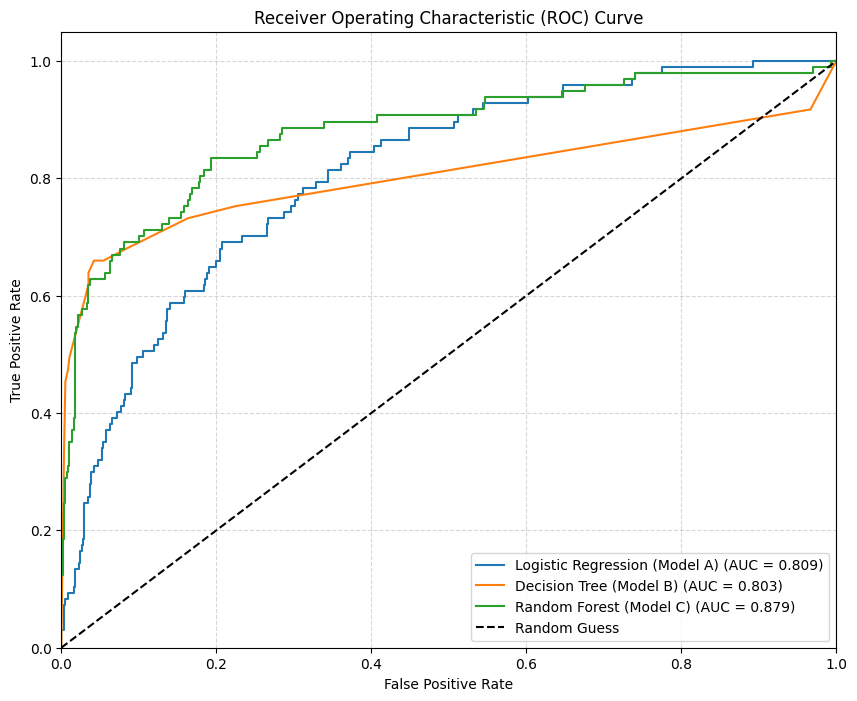

In [10]:
models = {
    'Logistic Regression (Model A)': model_a,
    'Decision Tree (Model B)': model_b,
    'Random Forest (Model C)': model_c
}

metrics_summary = []

plt.figure(figsize=(10, 8))

for name, pipeline in models.items():
    # Predictions on test data
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # Metrics computation
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc_val = roc_auc_score(y_test, y_proba)

    metrics_summary.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc_val
    })

    # Compute ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

# Format and display metrics table
metrics_df = pd.DataFrame(metrics_summary)
display(metrics_df.round(4))

# ROC Curve aesthetics
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()